In [238]:
def sensor_metadata(dir_path: str | Path = "OBS_logs") -> pd.DataFrame:
    """Scans CSV log files in a directory and compiles a summary DataFrame containing

    filename, serial number, sensor type, cadence, LED current, note, start/end
    datetimes, and comment text.
    """
    dir_path = Path(dir_path)
    csv_files = sorted(
        list(dir_path.glob("*.CSV")) + list(dir_path.glob("*.csv"))
    )

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {dir_path.resolve()}")

    metadata = []

    for file_path in csv_files:
        header_comments = []
        header_info = {
            "serial_number": None,
            "sensor_type": None,
            "cadence": None,
            "led_current": None,
            "note": None,
        }

        # 1. Parse commented header lines starting with '#'
        with open(file_path, "r", encoding="utf-8", errors="replace") as f:
            for line in f:
                stripped = line.strip()
                if stripped.startswith("#"):
                    clean_line = stripped.lstrip("#").strip()
                    header_comments.append(clean_line)

                    # Extract metadata key-value pairs
                    if ":" in clean_line:
                        left, right = clean_line.split(":", 1)
                        key_lower = left.lower()
                        val = right.strip()

                        if "serial number" in key_lower:
                            header_info["serial_number"] = val
                        elif (
                            "sensor model" in key_lower
                            or "sensor type" in key_lower
                        ):
                            header_info["sensor_type"] = val
                        elif "cadence" in key_lower:
                            header_info["cadence"] = val
                        elif "led current" in key_lower:
                            header_info["led_current"] = val
                        elif "note" in key_lower or "notes" in key_lower:
                            header_info["note"] = val
                else:
                    # Stop reading header once CSV data rows begin
                    break

        # 2. Process data using read_sensor_csv to derive datetimes & fallback columns
        df = read_sensor_csv(file_path)

        # Fallbacks if header comments were missing SN or sensor type
        if not header_info["serial_number"]:
            header_info["serial_number"] = (
                df["serial_number"].iloc[0]
                if "serial_number" in df.columns
                else file_path.stem.split("_")[0]
            )

        if not header_info["sensor_type"]:
            if (
                "sensor_type" in df.columns
                and not df["sensor_type"].dropna().empty
            ):
                header_info["sensor_type"] = str(df["sensor_type"].iloc[0])
            else:
                header_info["sensor_type"] = "UNKNOWN"

        # 3. Extract time bounds
        if isinstance(df.index, pd.DatetimeIndex) and not df.empty:
            start_dt = df.index.min()
            end_dt = df.index.max()
        else:
            start_dt = pd.NaT
            end_dt = pd.NaT

        metadata.append(
            {
                "filename": file_path.name,
                "serial_number": header_info["serial_number"],
                "sensor_type": header_info["sensor_type"],
                "cadence": header_info["cadence"],
                "led_current": header_info["led_current"],
                "note": header_info["note"],
                "start_datetime": start_dt,
                "end_datetime": end_dt,
                "comment": "\n".join(header_comments),
            }
        )

    return pd.DataFrame(metadata)

meta_df = sensor_metadata()
meta_df

Reading sensor log file... OBS_logs\133_1016.CSV
Reading sensor log file... OBS_logs\133_1016.CSV
Reading sensor log file... OBS_logs\133_1017.CSV
Reading sensor log file... OBS_logs\133_1017.CSV
Reading sensor log file... OBS_logs\138_1001.CSV
Reading sensor log file... OBS_logs\138_1001.CSV
Reading sensor log file... OBS_logs\141_2010.CSV
Reading sensor log file... OBS_logs\141_2010.CSV
Reading sensor log file... OBS_logs\146_1029.CSV
Reading sensor log file... OBS_logs\146_1029.CSV
Reading sensor log file... OBS_logs\146_3011.CSV
Reading sensor log file... OBS_logs\146_3011.CSV
Reading sensor log file... OBS_logs\147_4001.CSV
Reading sensor log file... OBS_logs\147_4001.CSV


,filename,serial_number,sensor_type,cadence,led_current,note,start_datetime,end_datetime,comment
0,133_1016.CSV,133,VCNL4010,100 ms,50 mA,concurrent.,2026-10-21 04:57:31.696000099,2026-10-21 04:59:11.596999884,OpenOBS Log File - Serial Number: 133\nSensor ...
1,133_1016.CSV,133,VCNL4010,100 ms,50 mA,concurrent.,2026-10-21 04:57:31.696000099,2026-10-21 04:59:11.596999884,OpenOBS Log File - Serial Number: 133\nSensor ...
2,133_1017.CSV,133,VCNL4010,100 ms,200 mA,"4010, longer test",2026-10-21 05:21:05.709000111,2026-10-21 14:58:06.898999929,OpenOBS Log File - Serial Number: 133\nSensor ...
3,133_1017.CSV,133,VCNL4010,100 ms,200 mA,"4010, longer test",2026-10-21 05:21:05.709000111,2026-10-21 14:58:06.898999929,OpenOBS Log File - Serial Number: 133\nSensor ...
4,138_1001.CSV,138,VCNL4010,100 ms,200 mA,"Concurrent, high power.",2026-10-21 04:55:11.099999905,2026-10-21 05:01:51.000999928,OpenOBS Log File - Serial Number: 138\nSensor ...
5,138_1001.CSV,138,VCNL4010,100 ms,200 mA,"Concurrent, high power.",2026-10-21 04:55:11.099999905,2026-10-21 05:01:51.000999928,OpenOBS Log File - Serial Number: 138\nSensor ...
6,141_2010.CSV,141,VCNL4020,100 ms,200 mA,4020,2026-10-21 05:19:52.292999983,2026-10-21 14:28:12.000000000,OpenOBS Log File - Serial Number: 141\nSensor ...
7,141_2010.CSV,141,VCNL4020,100 ms,200 mA,4020,2026-10-21 05:19:52.292999983,2026-10-21 14:28:12.000000000,OpenOBS Log File - Serial Number: 141\nSensor ...
8,146_1029.CSV,146,VCNL4010,100 ms,10 mA,Concurrent.,2026-10-21 04:51:14.289000034,2026-10-21 05:00:34.000999928,OpenOBS Log File - Serial Number: 146\nSensor ...
9,146_1029.CSV,146,VCNL4010,100 ms,10 mA,Concurrent.,2026-10-21 04:51:14.289000034,2026-10-21 05:00:34.000999928,OpenOBS Log File - Serial Number: 146\nSensor ...


In [239]:
from pathlib import Path
import pandas as pd


def read_sensor_csv(file_path: str | Path) -> pd.DataFrame:
    """Reads a single VCNL sensor log CSV into a formatted Pandas DataFrame,

    extracting header metadata (serial_number, sensor_type, cadence, led_current).
    """
    file_path = Path(file_path)
    print(f"Reading sensor log file... {file_path}")

    # 1. Parse metadata key-value pairs from commented header lines
    header_sn = None
    header_sensor_type = None
    cadence = None
    led_current = None

    with open(file_path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            stripped = line.strip()
            if stripped.startswith("#"):
                clean_line = stripped.lstrip("#").strip()
                if ":" in clean_line:
                    left, right = clean_line.split(":", 1)
                    key_lower = left.lower()
                    val = right.strip()

                    if "serial number" in key_lower:
                        header_sn = val
                    elif (
                        "sensor model" in key_lower
                        or "sensor type" in key_lower
                    ):
                        header_sensor_type = val
                    elif "cadence" in key_lower:
                        cadence = val
                    elif "led current" in key_lower:
                        led_current = val
            else:
                break

    # 2. Load CSV data ignoring header comments
    df = pd.read_csv(file_path, comment="#")

    # Standardize column name for light reading
    if "ambient_light" in df.columns:
        df.rename(columns={"ambient_light": "als"}, inplace=True)

    # Serial number: header comment priority, fallback to filename prefix
    serial_num = header_sn if header_sn else file_path.stem.split("_")[0]
    df["serial_number"] = serial_num

    # Sensor type: header comment priority, fallback to existing CSV column
    if header_sensor_type and "sensor_type" not in df.columns:
        df["sensor_type"] = header_sensor_type

    # Attach cadence and LED current metadata
    df["cadence"] = cadence
    df["led_current"] = led_current

    # # Construct high-precision datetime index if time was synced
    # if "timestamp" in df.columns and (df["timestamp"] > 0).any():
    #     sync_idx = (df["timestamp"] > 0).idxmax()
    #     base_epoch = df.loc[sync_idx, "timestamp"]
    #     base_millis = df.loc[sync_idx, "millis"]
    #
    #     millis_delta = df["millis"] - base_millis
    #     df["datetime"] = pd.to_datetime(
    #         base_epoch, unit="s"
    #     ) + pd.to_timedelta(millis_delta, unit="ms")
    #     df.set_index("datetime", inplace=True)

    # Parse timestamp column directly into DatetimeIndex
    if "timestamp" in df.columns and (df["timestamp"] > 0).any():
        df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")
        df.set_index("datetime", inplace=True)

    return df



from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from zoneinfo import ZoneInfo


def load_synchronized_master(
    dir_path: str | Path = "OBS_logs", grid_freq: str = "50ms"
) -> pd.DataFrame:
    """Stitches sequential logs per unique sensor configuration (SN, Model, Cadence, LED Current),

    uniquely prefixes columns, and aligns all sensors side-by-side onto a single timeline.
    """
    dir_path = Path(dir_path)
    csv_files = list(dir_path.glob("*.CSV")) + list(dir_path.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {dir_path.resolve()}")

    # 1. Parse all CSV files
    raw_dfs = [read_sensor_csv(f) for f in csv_files]

    # 2. Group files by (Serial Number, Sensor Model, Cadence, LED Current)
    sensor_groups = {}
    for df in raw_dfs:
        sn = df["serial_number"].iloc[0]
        sensor_type = (
            df["sensor_type"].iloc[0]
            if "sensor_type" in df.columns
            else "UNKNOWN"
        )
        cadence = (
            df["cadence"].iloc[0]
            if "cadence" in df.columns and df["cadence"].iloc[0]
            else "NA"
        )
        led_current = (
            df["led_current"].iloc[0]
            if "led_current" in df.columns and df["led_current"].iloc[0]
            else "NA"
        )

        sensor_key = (sn, sensor_type, cadence, led_current)

        # Retain numerical measurement columns only
        measurement_cols = [
            c
            for c in ["proximity", "als", "lux", "white"]
            if c in df.columns
        ]
        df_measurements = df[measurement_cols]

        if sensor_key not in sensor_groups:
            sensor_groups[sensor_key] = []
        sensor_groups[sensor_key].append(df_measurements)

    # 3. Stitch sequential logs per configuration & prefix column names
    processed_sensors = []
    for (
        sn,
        sensor_type,
        cadence,
        led_current,
    ), df_list in sensor_groups.items():
        combined_sensor = pd.concat(df_list, axis=0).sort_index()

        # Snap timestamps to grid to align independent microcontroller clocks
        if isinstance(combined_sensor.index, pd.DatetimeIndex):
            combined_sensor.index = combined_sensor.index.round(grid_freq)
            combined_sensor = combined_sensor.groupby(
                combined_sensor.index
            ).mean()

        # Clean string formatting for prefix (e.g., "SN146_VCNL4040_20ms_50mA")
        cad_str = str(cadence).replace(" ", "")
        led_str = str(led_current).replace(" ", "")
        prefix = f"SN{sn}_{sensor_type}_{cad_str}_{led_str}"
        combined_sensor = combined_sensor.add_prefix(f"{prefix}_")

        processed_sensors.append(combined_sensor)

    # 4. Synchronize all configurations horizontally (outer join on DatetimeIndex)
    master_df = pd.concat(processed_sensors, axis=1).sort_index()

    return master_df



# ==========================================
# Example Usage
# ==========================================
if __name__ == "__main__":
    # Load all sensors synchronized side-by-side
    master_df = load_synchronized_master("OBS_logs", grid_freq="50ms")

    print("--- Synchronized Master DataFrame ---")
    print(master_df.head(10))
    print("\nMaster Columns:")
    for col in master_df.columns:
        print(f" - {col}")

Reading sensor log file... OBS_logs\133_1016.CSV
Reading sensor log file... OBS_logs\133_1017.CSV
Reading sensor log file... OBS_logs\138_1001.CSV
Reading sensor log file... OBS_logs\141_2010.CSV
Reading sensor log file... OBS_logs\146_1029.CSV
Reading sensor log file... OBS_logs\146_3011.CSV
Reading sensor log file... OBS_logs\147_4001.CSV
Reading sensor log file... OBS_logs\133_1016.CSV
Reading sensor log file... OBS_logs\133_1017.CSV
Reading sensor log file... OBS_logs\138_1001.CSV
Reading sensor log file... OBS_logs\141_2010.CSV
Reading sensor log file... OBS_logs\146_1029.CSV
Reading sensor log file... OBS_logs\146_3011.CSV
Reading sensor log file... OBS_logs\147_4001.CSV
--- Synchronized Master DataFrame ---
                         SN133_VCNL4010_100ms_50mA_proximity  \
datetime                                                       
2026-10-20 22:13:20.000                                  NaN   
2026-10-21 04:51:14.300                                  NaN   
2026-10-21 04:51:14.

C:\Users\kvc2\AppData\Local\Temp\ipykernel_35616\862432412.py:166: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  master_df = pd.concat(processed_sensors, axis=1).sort_index()


In [241]:
print(meta_df.iloc[0].comment)

OpenOBS Log File - Serial Number: 133
Sensor Model: VCNL4010
Cadence: 100 ms
LED Current: 50 mA
Notes: concurrent.


In [242]:
import plotly.express as px
fig = px.timeline(
    meta_df,
    x_start="start_datetime",
    x_end="end_datetime",
    y="serial_number",
    color="sensor_type",  # Groups and colors bars by resource/department
    title="File Overview"
)
fig.write_html("OBS_data_overview.html")

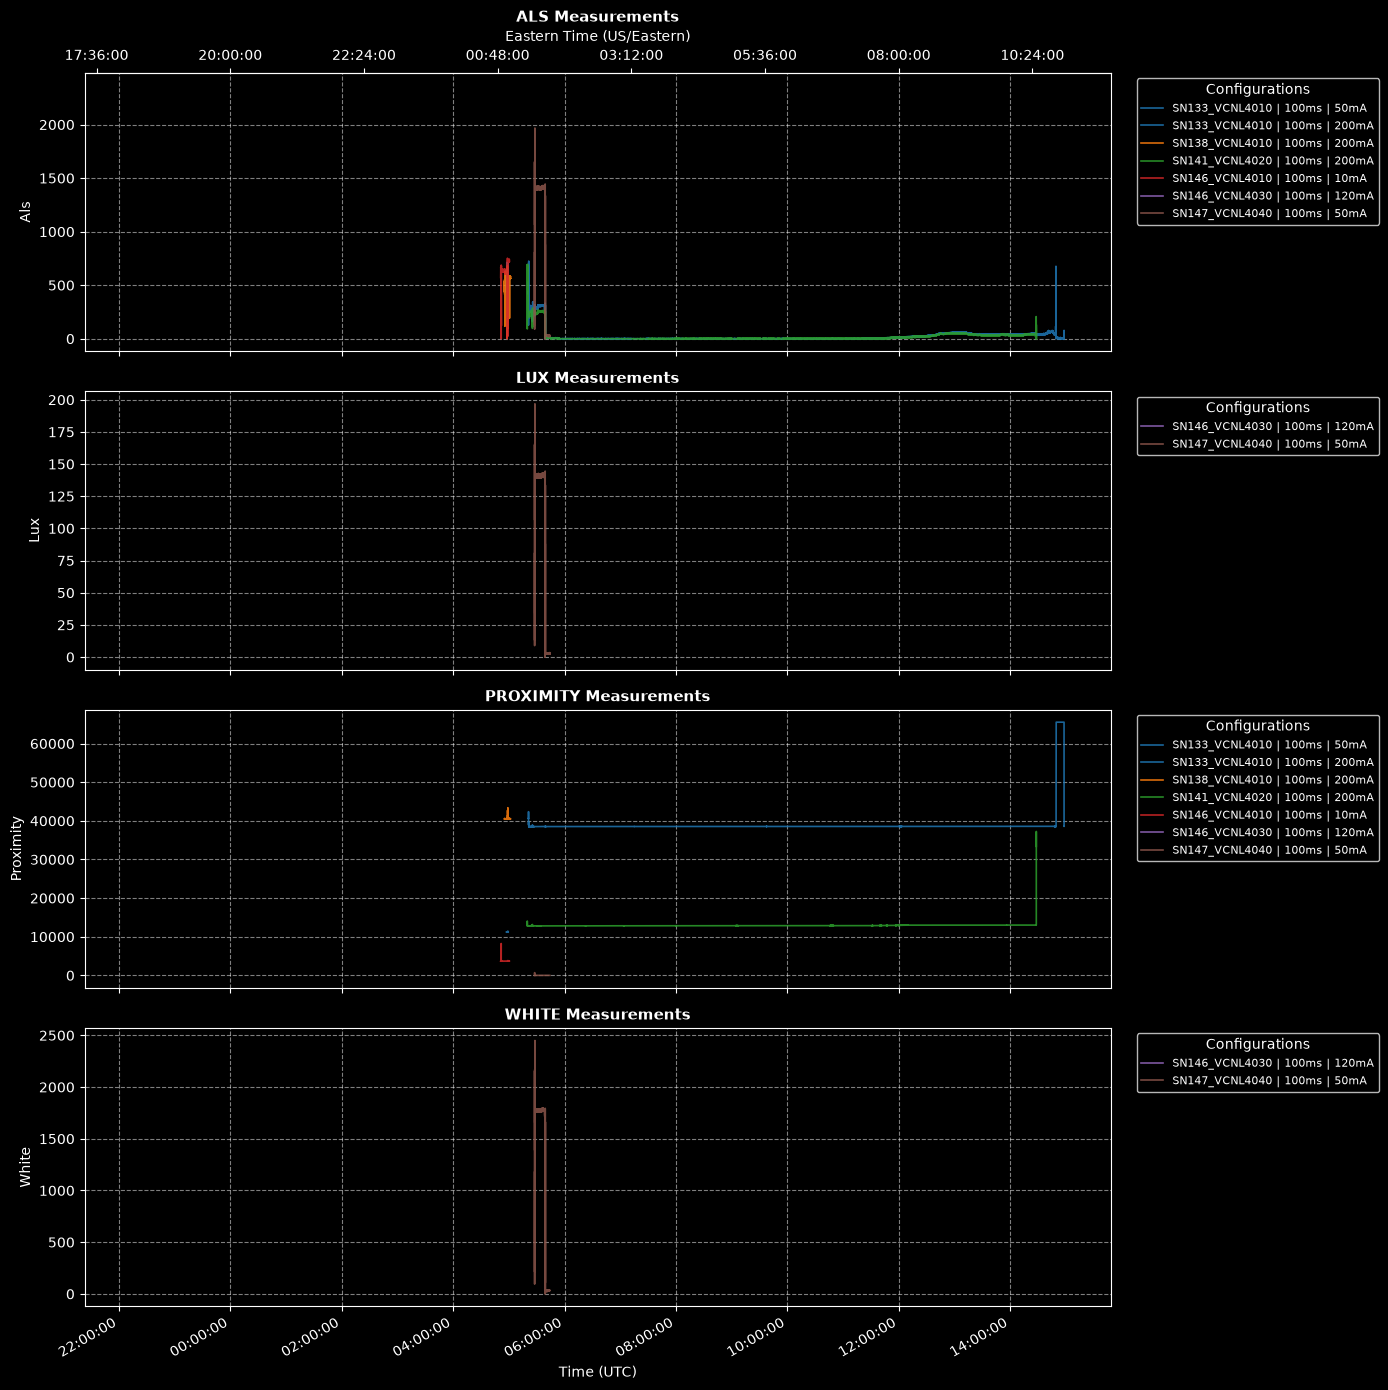

In [243]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from zoneinfo import ZoneInfo


import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from zoneinfo import ZoneInfo


def plot_synchronized_sensors(
    df: pd.DataFrame, smooth_window: str | None = None
):
    """Plots synchronized sensor time series split by measurement metric.

    Strips outer-join NaNs per series so overlapping concurrent runs connect
    smoothly.
    """
    if df.empty:
        print("DataFrame is empty.")
        return

    # 1. Isolate numeric measurement columns
    numeric_cols = df.select_dtypes(include="number").columns
    if numeric_cols.empty:
        print("No numeric measurement data found to plot.")
        return

    known_metrics = ["proximity", "als", "lux", "white"]

    # 2. Parse column metadata
    parsed_cols = []
    for col in numeric_cols:
        metric = None
        for m in known_metrics:
            if col.endswith(f"_{m}"):
                metric = m
                break
        if not metric:
            metric = col.rsplit("_", 1)[-1]

        config_prefix = col.rsplit(f"_{metric}", 1)[0]

        try:
            base_sensor, cadence, led_current = config_prefix.rsplit("_", 2)
        except ValueError:
            base_sensor = config_prefix
            cadence = "NA"
            led_current = "NA"

        parsed_cols.append(
            {
                "col": col,
                "metric": metric,
                "config_prefix": config_prefix,
                "base_sensor": base_sensor,
                "cadence": cadence,
                "led_current": led_current,
            }
        )

    metrics = sorted(list({p["metric"] for p in parsed_cols}))
    unique_sensors = sorted(list({p["base_sensor"] for p in parsed_cols}))
    unique_cadences = sorted(list({p["cadence"] for p in parsed_cols}))

    # 3. Color & Style mappings
    color_palette = plt.cm.tab10.colors
    sensor_color_map = {
        s: color_palette[i % len(color_palette)]
        for i, s in enumerate(unique_sensors)
    }

    linestyles = ["-", "--", ":", "-."]
    cadence_style_map = {
        c: linestyles[i % len(linestyles)]
        for i, c in enumerate(unique_cadences)
    }

    fig, axes = plt.subplots(
        nrows=len(metrics),
        ncols=1,
        figsize=(14, 3.5 * len(metrics)),
        sharex=True,
    )

    if len(metrics) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        metric_items = [p for p in parsed_cols if p["metric"] == metric]

        for item in metric_items:
            col = item["col"]

            # CRITICAL FIX: Extract series and drop outer-join NaNs for this specific sensor
            series = df[col].dropna()
            if series.empty:
                continue

            # Apply rolling filter on valid values only
            if smooth_window:
                series = series.rolling(smooth_window).mean()

            color = sensor_color_map[item["base_sensor"]]
            linestyle = cadence_style_map[item["cadence"]]
            label = f"{item['base_sensor']} | {item['cadence']} | {item['led_current']}"

            ax.plot(
                series.index,
                series.values,
                label=label,
                alpha=0.85,
                linewidth=1.2,
                color=color,
                linestyle=linestyle,
            )

        ax.set_title(
            f"{metric.upper()} Measurements", fontsize=11, fontweight="bold"
        )
        ax.set_ylabel(metric.capitalize(), fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)

        ax.legend(
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            framealpha=0.9,
            fontsize=8,
            title="Configurations",
        )

    # Format x-axis (UTC)
    axes[-1].set_xlabel("Time (UTC)", fontsize=10)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    fig.autofmt_xdate()

    # Secondary x-axis (Eastern Time)
    secax_et = axes[0].secondary_xaxis("top")
    secax_et.xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S", tz=ZoneInfo("America/New_York"))
    )
    secax_et.set_xlabel("Eastern Time (US/Eastern)", fontsize=10, labelpad=6)

    plt.tight_layout()
    plt.show()

# Example Usage:
plot_synchronized_sensors(master_df)
# plot_synchronized_sensors(master_df, smooth_window="250ms")

### Filter to a particular timerange and discard sensor columns we're not using:

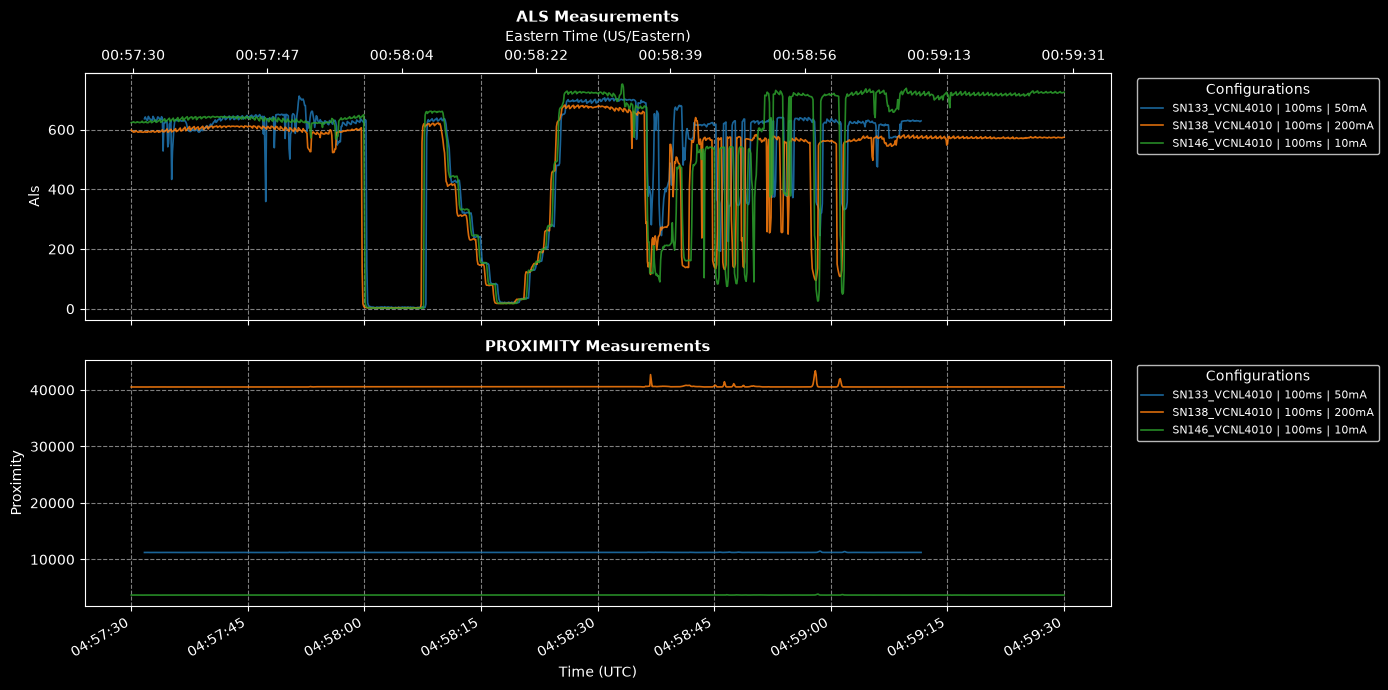

In [248]:
start = pd.Timestamp("2026-10-21 04:57:30")
end = pd.Timestamp("2026-10-21 04:59:30")


df_filtered = master_df.sort_index().loc[start:end]
df_filtered.dropna(how='all', axis=1, inplace=True) # drop empty columns

plot_synchronized_sensors(df_filtered)


In [249]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_interactive_sensors(df: pd.DataFrame):
    """Creates an interactive multi-panel time-series chart with linked zoom controls."""
    metrics = sorted(list({col.rsplit("_", 1)[-1] for col in df.columns}))

    fig = make_subplots(
        rows=len(metrics),
        cols=1,
        shared_xaxes=True,
        subplot_titles=[f"{m.upper()} Readings" for m in metrics],
        vertical_spacing=0.08,
    )

    for row_idx, metric in enumerate(metrics, start=1):
        metric_cols = [c for c in df.columns if c.endswith(f"_{metric}")]

        for col in metric_cols:
            sensor_label = col.rsplit(f"_{metric}", 1)[0]
            fig.add_trace(
                go.Scatter(
                    x=df.index,
                    y=df[col],
                    mode="lines",
                    name=f"{sensor_label} ({metric})",
                    legendgroup=sensor_label,
                ),
                row=row_idx,
                col=1,
            )

    fig.update_layout(
        height=300 * len(metrics),
        title_text="Synchronized VCNL Sensor Telemetry",
        hovermode="x unified",
        template="plotly_white",
    )

    # fig.show()
    print("Writing to file...")
    fig.write_html("interactive_sensors.html")


# Example Usage:
plot_interactive_sensors(df_filtered)

Writing to file...
